# KT-02 · Notebook 02 — So sánh 7 hàm kích hoạt (PHẦN 2)

In [1]:
import sys, os, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
sys.path.insert(0, "../src")            # import code trong src/
os.makedirs("../reports", exist_ok=True)
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

In [2]:
from nn_numpy import ACTIVATIONS, PRETTY
from nn_numpy import DeepNet
from nn_numpy import fit, dead_neurons, layer_grad_norms, accuracy
from nn_numpy import load_image_data, moons
Xtr, Xva, ytr, yva, ten_data = load_image_data()
print("Dữ liệu:", ten_data, "| train", Xtr.shape, "| val", Xva.shape)

da check xong
Dữ liệu: sklearn digits (8×8) — thay MNIST | train (1347, 64) | val (450, 64)


## Bước 6 — Đồ thị 7 hàm kích hoạt và đạo hàm trên cùng hệ trục

Nét liền = hàm, nét đứt = đạo hàm (cùng màu). Đạo hàm giải tích được đối chiếu với đạo hàm số để chắc chắn cài đúng.

,hàm,đạo hàm tối đa,đạt tại z,sai lệch so với đạo hàm số (|z|>1e-3)
0,Sigmoid,0.250,0.00,1.3e-10
1,Tanh,1.000,0.00,7.1e-11
2,ReLU,1.000,0.01,1.4e-10
3,LeakyReLU,1.000,0.01,1.4e-10
4,ELU,1.000,0.00,1.4e-10
5,GELU,1.129,1.41,6.1e-10
6,SiLU/Swish,1.100,2.40,8.1e-10


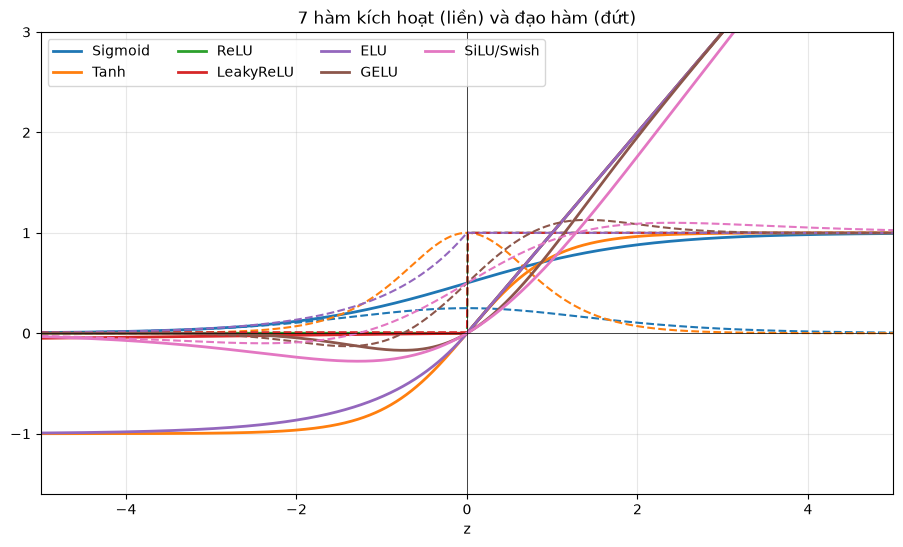

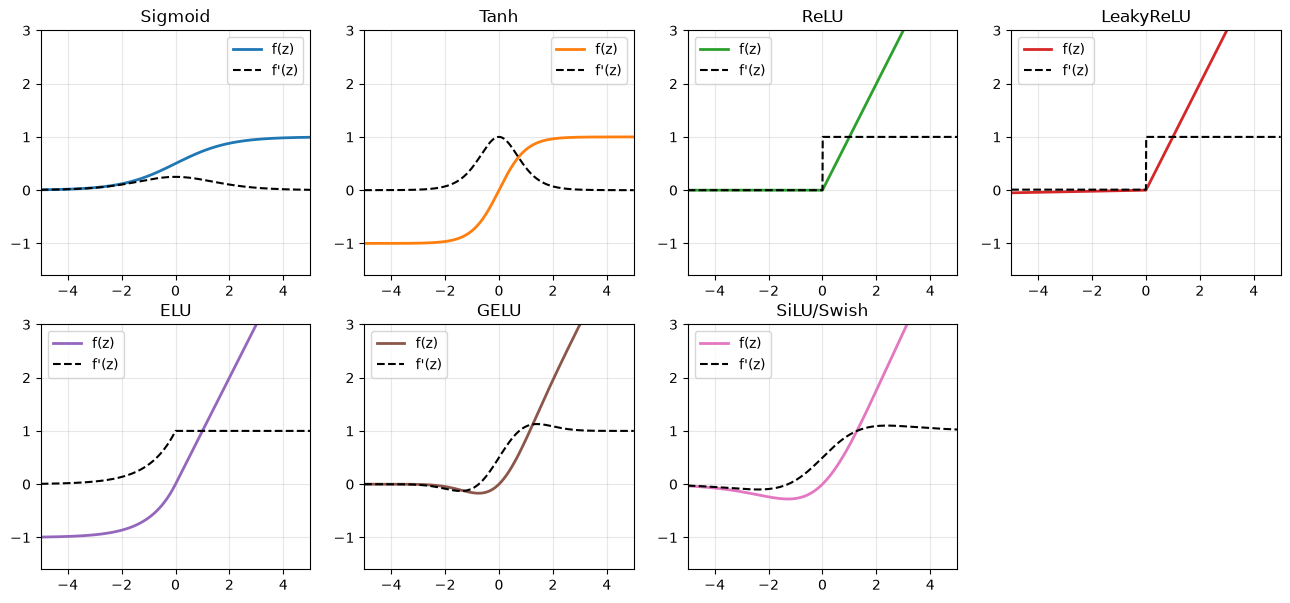

In [3]:
z = np.linspace(-5, 5, 1001)
colors = plt.cm.tab10(np.arange(7))
fig, ax = plt.subplots(figsize=(11, 6))
rows = []
for (name, (f, df)), c in zip(ACTIVATIONS.items(), colors):
    ax.plot(z, f(z), color=c, lw=2, label=PRETTY[name])
    ax.plot(z, df(z), color=c, lw=1.5, ls="--")
    num = (f(z + 1e-6) - f(z - 1e-6)) / 2e-6
    ok = np.abs(z) > 1e-3                      # bỏ điểm gấp khúc z=0 của ReLU/LeakyReLU (không khả vi)
    rows.append((PRETTY[name], f"{df(z).max():.3f}", f"{z[np.argmax(df(z))]:.2f}", f"{np.abs(num - df(z))[ok].max():.1e}"))
ax.set(ylim=(-1.6, 3), xlim=(-5, 5), xlabel="z", title="7 hàm kích hoạt (liền) và đạo hàm (đứt)")
ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5); ax.legend(ncol=4, loc="upper left")
plt.savefig("../reports/7_activations.png", bbox_inches="tight")

fig, axs = plt.subplots(2, 4, figsize=(16, 7)); axs = axs.ravel()
for a, (name, (f, df)), c in zip(axs, ACTIVATIONS.items(), colors):
    a.plot(z, f(z), color=c, lw=2, label="f(z)"); a.plot(z, df(z), "k--", lw=1.5, label="f'(z)")
    a.set(title=PRETTY[name], ylim=(-1.6, 3), xlim=(-5, 5)); a.legend()
axs[-1].axis("off")

pd.DataFrame(rows, columns=["hàm", "đạo hàm tối đa", "đạt tại z", "sai lệch so với đạo hàm số (|z|>1e-3)"])

Điểm cần nhớ từ bảng: đạo hàm tối đa của Sigmoid là **0.25**, Tanh là **1.0**, ReLU là **1** (vùng dương); GELU và SiLU **vượt 1 một chút** (~1.13 và ~1.10).

## Bước 7 — So sánh 7 activation trên dữ liệu ảnh

**Chỉ đổi activation**, giữ nguyên mọi thứ khác: kiến trúc 64→128→64→10, khởi tạo Xavier cho cả 7, SGD `lr=0.1`, batch 64, 60 epoch, cùng seed.
Chạy 3 seed, báo cáo trung bình ± độ lệch chuẩn. "Epoch hội tụ" = epoch đầu tiên có val accuracy ≥ 95%.

,activation,val acc (%),epoch tới ≥95%,loss cuối,thời gian (s)
0,Sigmoid,88.52 ± 0.46,không đạt (0/3),0.5136,1.4
1,Tanh,97.33 ± 0.31,8.0 (3/3 seed đạt),0.0386,1.4
2,ReLU,97.41 ± 0.21,8.7 (3/3 seed đạt),0.0292,0.8
3,LeakyReLU,97.41 ± 0.21,8.7 (3/3 seed đạt),0.0295,0.9
4,ELU,97.11 ± 0.18,7.3 (3/3 seed đạt),0.0328,1.5
5,GELU,96.96 ± 0.28,9.7 (3/3 seed đạt),0.0321,1.6
6,SiLU/Swish,96.67 ± 0.63,10.7 (3/3 seed đạt),0.0413,1.4


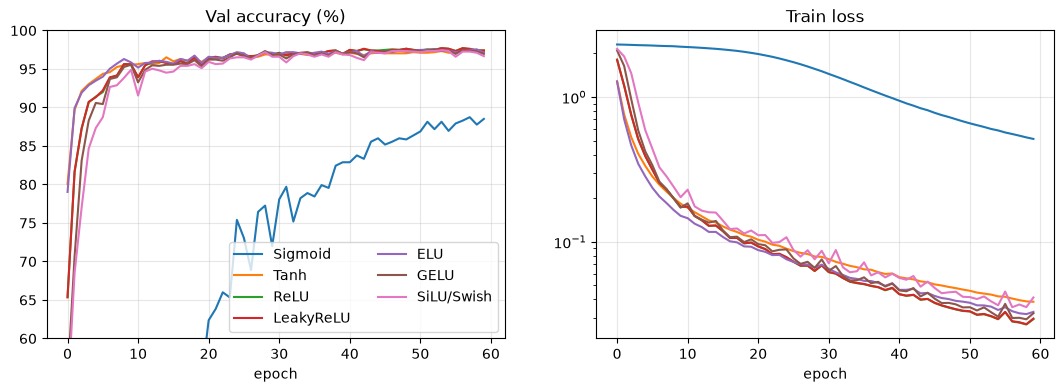

In [4]:
SEEDS, EPOCHS = [0, 1, 2], 60
runs = {}
for name in ACTIVATIONS:
    runs[name] = []
    for s in SEEDS:
        net = DeepNet([Xtr.shape[1], 128, 64, 10], act=name, init="xavier", seed=s)
        runs[name].append(fit(net, Xtr, ytr, Xva, yva, epochs=EPOCHS, lr=0.1, batch=64, seed=s, thr=0.95))
rows = []
for name, hs in runs.items():
    acc = np.array([h["val_acc"][-1] for h in hs]) * 100
    ep = [h["epoch_thr"] for h in hs]
    ep_ok = [e for e in ep if e is not None]
    rows.append({"activation": PRETTY[name], "val acc (%)": f"{acc.mean():.2f} ± {acc.std():.2f}",
                 "epoch tới ≥95%": f"{np.mean(ep_ok):.1f} ({len(ep_ok)}/{len(ep)} seed đạt)" if ep_ok else f"không đạt (0/{len(ep)})",
                 "loss cuối": f"{np.mean([h['loss'][-1] for h in hs]):.4f}",
                 "thời gian (s)": f"{np.mean([h['time'] for h in hs]):.1f}"})
tbl = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, hs in runs.items():
    ax[0].plot(np.mean([h["val_acc"] for h in hs], 0) * 100, label=PRETTY[name])
    ax[1].plot(np.mean([h["loss"] for h in hs], 0), label=PRETTY[name])
ax[0].set(title="Val accuracy (%)", xlabel="epoch", ylim=(60, 100)); ax[1].set(title="Train loss", xlabel="epoch", yscale="log"); ax[0].legend(ncol=2)

tbl

### Thêm: ranh giới quyết định của 7 activation trên `make_moons` (1.000 điểm)

(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

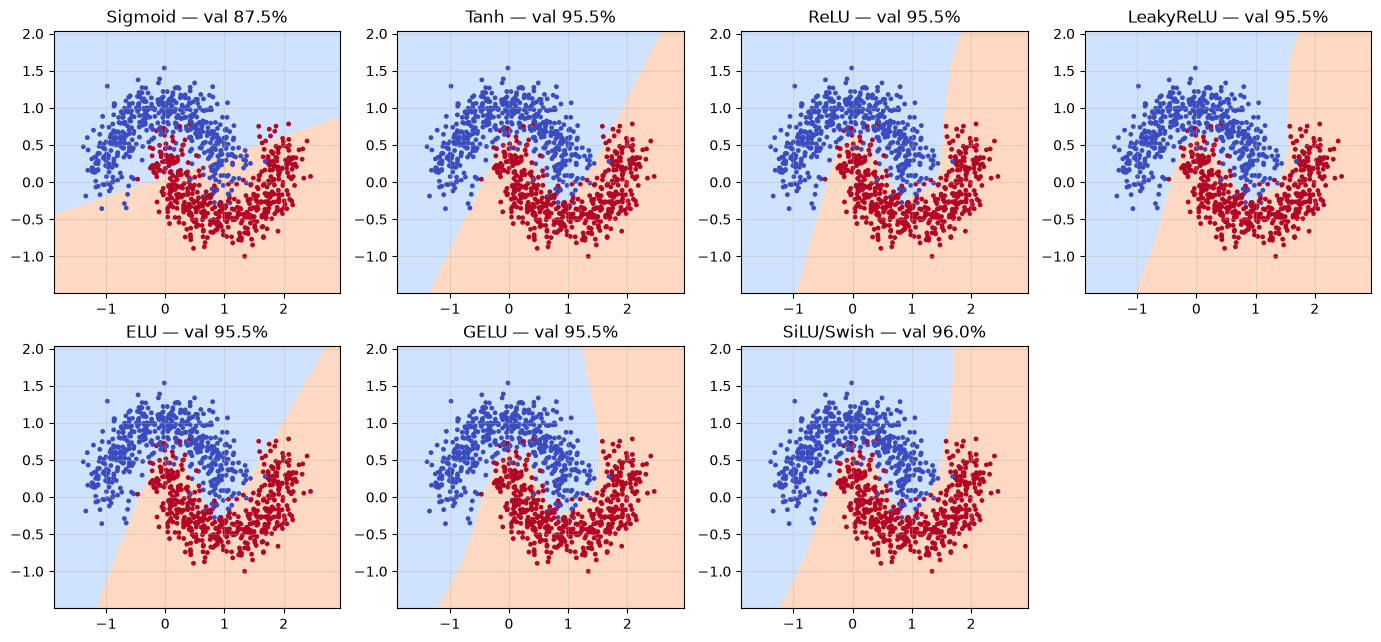

In [5]:
Xm, ym = moons(1000, noise=0.2)
fig, axs = plt.subplots(2, 4, figsize=(17, 7.5)); axs = axs.ravel()
g = np.linspace(Xm[:, 0].min() - .5, Xm[:, 0].max() + .5, 200); h_ = np.linspace(Xm[:, 1].min() - .5, Xm[:, 1].max() + .5, 200)
xx, yy = np.meshgrid(g, h_)
for a, name in zip(axs, ACTIVATIONS):
    net = DeepNet([2, 16, 16, 2], act=name, init="xavier", seed=0)
    h = fit(net, Xm[:800], ym[:800], Xm[800:], ym[800:], epochs=150, lr=0.1, batch=32, seed=0)
    Z = net.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    a.contourf(xx, yy, Z, levels=[-.5, .5, 1.5], colors=["#cfe3ff", "#ffd9c2"]); a.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap="coolwarm", s=6)
    a.set_title(f"{PRETTY[name]} — val {h['val_acc'][-1]:.1%}")
axs[-1].axis("off")

## Bước 8 — Vanishing gradient: mạng 15 tầng, |gradient| theo tầng

Mạng `[64] + 15×[64 neuron] + [10]` (15 tầng ẩn + 1 tầng đầu ra). Với mỗi cấu hình, đo chuẩn của gradient `W` ở **từng tầng** (tầng 1 = gần đầu vào nhất),
trung bình 5 seed × 256 mẫu. Đường chấm: lý thuyết `0.25^k` (mỗi tầng sigmoid nhân tối đa 0.25).

0.25^10 = 9.54e-07 (README: ≈ 0,00000095)


,cấu hình,|grad| tầng 1,|grad| tầng cuối,tỉ lệ cuối/đầu
0,Sigmoid (He),2.4e-08,9.5e-01,4.0e+07
1,Sigmoid (Xavier),3.5e-10,8.2e-01,2.3e+09
2,Tanh (Xavier),3.1e-01,2.1e-01,6.6e-01
3,ReLU (He),1.7e+00,2.1e+00,1.2e+00


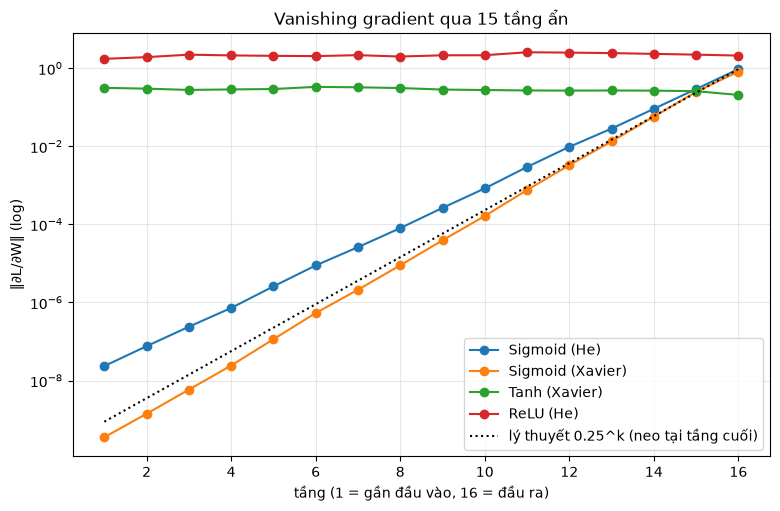

In [6]:
def gradient_theo_tang(act, init, depth=15, width=64, seeds=5):
    out = []
    for s in range(seeds):
        net = DeepNet([Xtr.shape[1]] + [width] * depth + [10], act=act, init=init, seed=s)
        idx = np.random.RandomState(s).choice(len(Xtr), 256, replace=False)
        out.append(layer_grad_norms(net, Xtr[idx], ytr[idx]))
    return np.mean(out, axis=0)

cfgs = [("sigmoid", "he", "Sigmoid (He)"), ("sigmoid", "xavier", "Sigmoid (Xavier)"),
        ("tanh", "xavier", "Tanh (Xavier)"), ("relu", "he", "ReLU (He)")]
gn = {lab: gradient_theo_tang(a, i) for a, i, lab in cfgs}
tang = np.arange(1, 17)
fig, ax = plt.subplots(figsize=(9, 5.5))
for lab, g_ in gn.items():
    ax.semilogy(tang, g_, "o-", label=lab)
ref = gn["Sigmoid (He)"][-1] * 0.25 ** (16 - tang)
ax.semilogy(tang, ref, "k:", label="lý thuyết 0.25^k (neo tại tầng cuối)")
ax.set(xlabel="tầng (1 = gần đầu vào, 16 = đầu ra)", ylabel="‖∂L/∂W‖ (log)", title="Vanishing gradient qua 15 tầng ẩn")
ax.legend(); plt.savefig("../reports/vanishing_gradient.png", bbox_inches="tight")
rows = [(lab, f"{g_[0]:.1e}", f"{g_[-1]:.1e}", f"{g_[-1] / g_[0]:.1e}") for lab, g_ in gn.items()]
print("0.25^10 =", f"{0.25 ** 10:.2e}", "(README: ≈ 0,00000095)")
pd.DataFrame(rows, columns=["cấu hình", "|grad| tầng 1", "|grad| tầng cuối", "tỉ lệ cuối/đầu"])

## Bước 9 — Tạo hiện tượng DYING ReLU và đếm % neuron chết

- **Neuron chết** = pre-activation ≤ 0 với **mọi** mẫu huấn luyện (ReLU: luôn xuất 0 ⇒ gradient = 0 ⇒ không bao giờ học lại).
  Với LeakyReLU cùng định nghĩa này nghĩa là "luôn ở nhánh âm", nhưng nhánh âm vẫn có độ dốc 0.01 nên gradient ≠ 0.
- Train 5 epoch với `lr` lớn dần (mạng 64→128→128→64→10, He init, 3 seed). Đo % neuron chết.
- Rồi **hạ lr về 0.05 và train thêm 30 epoch** để xem neuron có "sống lại" không.
- Nếu loss thành NaN/∞ (phân kỳ) thì ghi nhận là *phân kỳ* và **không** tính % chết cho lần chạy đó.

,activation,lr,số lần chạy,phân kỳ (NaN),% neuron chết sau lr lớn,% neuron chết sau hạ lr,val acc sau hạ lr (%)
0,ReLU,0.05,3,0,6.0,5.6,96.7
1,ReLU,0.20,3,0,2.2,3.1,97.3
2,ReLU,0.50,3,0,2.1,2.8,97.1
3,ReLU,1.00,3,0,42.1,39.6,91.9
4,ReLU,2.00,3,0,87.6,87.6,10.2
5,ReLU,5.00,3,0,87.3,87.3,10.1
6,LeakyReLU,0.05,3,0,5.7,5.6,96.6
7,LeakyReLU,0.20,3,0,2.3,3.1,97.2
8,LeakyReLU,0.50,3,0,2.8,3.4,97.2
9,LeakyReLU,1.00,3,1,42.7,44.2,84.0


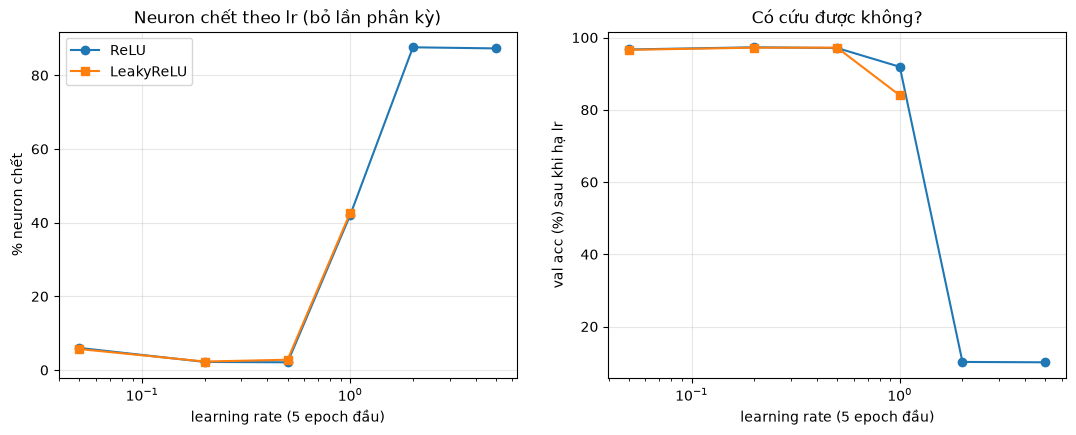

In [7]:
LRS, SEEDS = [0.05, 0.2, 0.5, 1.0, 2.0, 5.0], [0, 1, 2]
rows = []
for act in ["relu", "leaky_relu"]:
    for lr in LRS:
        chet, chet_sau, acc_sau, phan_ky = [], [], [], 0
        for s in SEEDS:
            net = DeepNet([Xtr.shape[1], 128, 128, 64, 10], act=act, init="he", seed=s)
            h = fit(net, Xtr, ytr, Xva, yva, epochs=5, lr=lr, seed=s)
            if h["diverged"]:
                phan_ky += 1; continue
            chet.append(dead_neurons(net, Xtr)[0] * 100)
            h2 = fit(net, Xtr, ytr, Xva, yva, epochs=30, lr=0.05, seed=s)
            if h2["diverged"]:
                phan_ky += 1; continue
            chet_sau.append(dead_neurons(net, Xtr)[0] * 100); acc_sau.append(h2["val_acc"][-1] * 100)
        f = lambda v: round(float(np.mean(v)), 1) if v else np.nan
        rows.append({"activation": PRETTY[act], "lr": lr, "số lần chạy": len(SEEDS), "phân kỳ (NaN)": phan_ky,
                     "% neuron chết sau lr lớn": f(chet), "% neuron chết sau hạ lr": f(chet_sau), "val acc sau hạ lr (%)": f(acc_sau)})
dy = pd.DataFrame(rows)
dy.to_csv("../reports/dying_relu.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for act, m in [("ReLU", "o-"), ("LeakyReLU", "s-")]:
    d = dy[dy.activation == act]
    ax[0].plot(d.lr, d["% neuron chết sau lr lớn"], m, label=act)
    ax[1].plot(d.lr, d["val acc sau hạ lr (%)"], m, label=act)
ax[0].set(xscale="log", xlabel="learning rate (5 epoch đầu)", ylabel="% neuron chết", title="Neuron chết theo lr (bỏ lần phân kỳ)")
ax[1].set(xscale="log", xlabel="learning rate (5 epoch đầu)", ylabel="val acc (%) sau khi hạ lr", title="Có cứu được không?"); ax[0].legend()

dy